# Fuzzy Logic: Stok Suku Cadang (Mamdani FIS)

Marsa Naufal (04231047)

**Kasus:** manajer pusat servis peralatan listrik harus menentukan **berapa suku cadang (n)** yang disimpan agar pelanggan puas. Input:
- `m`: rata-rata waktu tunggu (*mean delay*)
- `s`: jumlah petugas servis (*servers*)
- `ρ`: faktor utilisasi perbaikan

Semua nilai sudah dinormalisasi ke [0, 1]. Pengerjaan memakai `scikit-fuzzy` (`pip install -U scikit-fuzzy`). Isi notebook:
1. **Problem 1**: hitung n untuk m=0.4, s=0.45, ρ=0.45.
2. **Problem 2**: permukaan 3D n untuk ρ=0 dan semua kombinasi m, s.
3. **Kasus tambahan**: risiko kredit pinjaman (pendapatan × rasio utang).

### Alur sistem inferensi Mamdani (dipakai di semua bagian)
| Langkah | Arti | Operasi |
|---|---|---|
| 1. Fuzzifikasi | angka tegas → derajat keanggotaan tiap himpunan linguistik | `interp_membership` |
| 2. Evaluasi anteseden | derajat penyulutan (*firing strength*) tiap aturan | `AND` = **min** |
| 3. Implikasi | potong himpunan konsekuen setinggi firing strength | `fmin(w, MF)` |
| 4. Agregasi | gabungkan semua himpunan konsekuen yang terpotong | `fmax` (union) |
| 5. Defuzzifikasi | himpunan hasil → satu angka tegas | **centroid** (titik berat) |

## 0. Library
`numpy` untuk array, `matplotlib` untuk grafik, `skfuzzy` untuk fungsi keanggotaan dan defuzzifikasi.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

## 1. Fungsi keanggotaan (*membership function*)
Tabel soal hanya memberi **rentang** tiap nilai linguistik, bukan bentuknya. Asumsi saya (harus disebut agar bisa diperiksa):
- Semua himpunan berbentuk **segitiga** `[a, puncak, c]`, dengan `a` dan `c` = batas rentang dari soal.
- Puncak di **tengah rentang**; jika rentang menyentuh batas semesta (0 atau 1), puncaknya di batas itu (bentuk "bahu"). Contoh: `VS` pada n berentang [0, 0.30] → `[0, 0, 0.30]`; `L` pada s berentang [0.60, 1] → `[0.60, 1, 1]`.

Semesta dibuat 0 sampai 1 dengan 1001 titik supaya centroid halus.

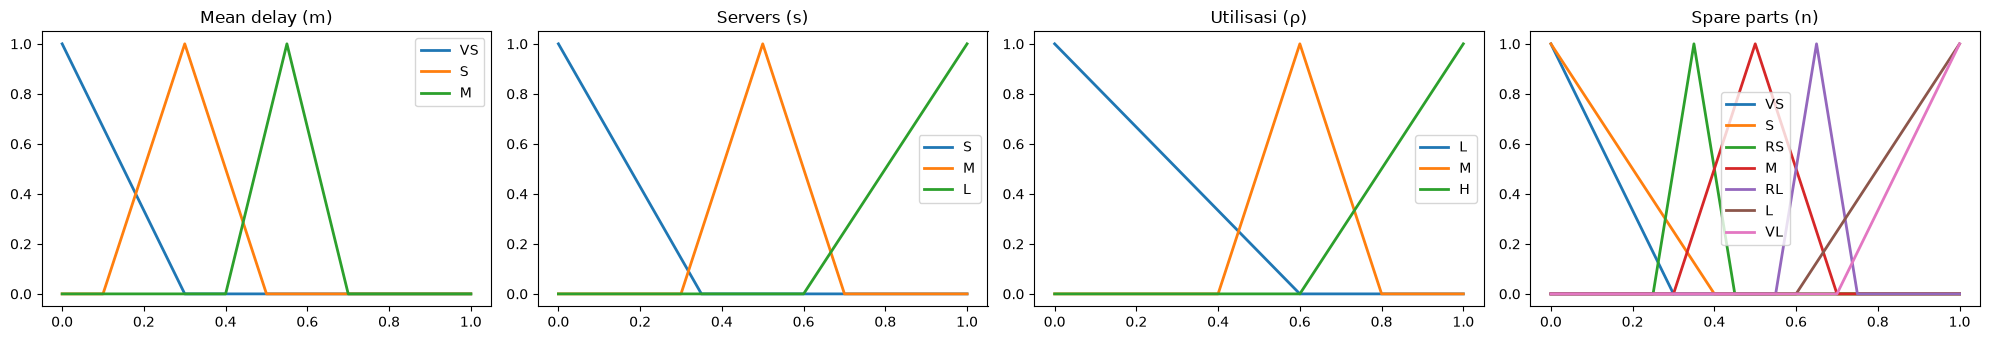

In [2]:
x = np.linspace(0, 1, 1001)
tri = lambda a, b, c: fuzz.trimf(x, [a, b, c])

mf = {
    'm':   {'VS': tri(0, 0, .30), 'S': tri(.10, .30, .50), 'M': tri(.40, .55, .70)},
    's':   {'S': tri(0, 0, .35), 'M': tri(.30, .50, .70), 'L': tri(.60, 1, 1)},
    'rho': {'L': tri(0, 0, .60), 'M': tri(.40, .60, .80), 'H': tri(.60, 1, 1)},
    'n':   {'VS': tri(0, 0, .30), 'S': tri(0, 0, .40), 'RS': tri(.25, .35, .45),
            'M': tri(.30, .50, .70), 'RL': tri(.55, .65, .75), 'L': tri(.60, 1, 1),
            'VL': tri(.70, 1, 1)},
}
titles = {'m': 'Mean delay (m)', 's': 'Servers (s)', 'rho': 'Utilisasi (ρ)', 'n': 'Spare parts (n)'}

fig, axs = plt.subplots(1, 4, figsize=(20, 3.5))
for ax, (var, sets) in zip(axs, mf.items()):
    for name, y in sets.items():
        ax.plot(x, y, label=name, lw=2)
    ax.set_title(titles[var]); ax.set_ylim(-.05, 1.05); ax.legend()
plt.tight_layout(); plt.show()

## 2. Basis aturan (12 aturan)
Tiap aturan ditulis sebagai `(anteseden, konsekuen)`. Anteseden berupa dict `{variabel: himpunan}`; jika berisi dua variabel, keduanya dihubungkan **AND**.

In [3]:
rules = [
    ({'rho': 'L'}, 'S'),                 # 1
    ({'rho': 'M'}, 'M'),                 # 2
    ({'rho': 'H'}, 'L'),                 # 3
    ({'m': 'VS', 's': 'S'}, 'VL'),       # 4
    ({'m': 'S',  's': 'S'}, 'L'),        # 5
    ({'m': 'M',  's': 'S'}, 'M'),        # 6
    ({'m': 'VS', 's': 'M'}, 'RL'),       # 7
    ({'m': 'S',  's': 'M'}, 'RS'),       # 8
    ({'m': 'M',  's': 'M'}, 'S'),        # 9
    ({'m': 'VS', 's': 'L'}, 'M'),        # 10
    ({'m': 'S',  's': 'L'}, 'S'),        # 11
    ({'m': 'M',  's': 'L'}, 'VS'),       # 12
]

## 3. Mesin inferensi
Fungsi `infer` menjalankan langkah 1–5 pada satu titik input:
- **Fuzzifikasi + evaluasi**: `interp_membership` memberi derajat tiap himpunan di nilai input; `min` untuk AND.
- **Implikasi**: `np.fmin(w, MF_konsekuen)` memotong konsekuen setinggi `w`.
- **Agregasi**: `np.fmax` menyatukan semua hasil potongan (union fuzzy, sesuai hint soal).
- **Defuzzifikasi**: `fuzz.defuzz(..., 'centroid')`. Jika tidak ada aturan menyala (agregat semua nol), centroid tidak terdefinisi dan dikembalikan `nan`.

In [4]:
def infer(m, s, rho):
    val = {'m': m, 's': s, 'rho': rho}
    agg = np.zeros_like(x)
    fired = []
    for ante, cons in rules:
        w = min(fuzz.interp_membership(x, mf[v][t], val[v]) for v, t in ante.items())
        fired.append(w)
        agg = np.fmax(agg, np.fmin(w, mf['n'][cons]))
    n = fuzz.defuzz(x, agg, 'centroid') if agg.any() else np.nan
    return n, agg, fired

## 4. Problem 1: m = 0.4, s = 0.45, ρ = 0.45
Pertama lihat **derajat keanggotaan** tiap input (hasil fuzzifikasi), lalu aturan mana yang menyala.

In [5]:
m0, s0, r0 = 0.4, 0.45, 0.45
for var, v in [('m', m0), ('s', s0), ('rho', r0)]:
    print(titles[var], '=', v, {k: round(float(fuzz.interp_membership(x, y, v)), 3) for k, y in mf[var].items()})

n0, agg0, fired0 = infer(m0, s0, r0)
print()
for i, ((ante, cons), w) in enumerate(zip(rules, fired0), 1):
    print(f"Aturan {i:2d}: IF {' AND '.join(f'{v}.{t}' for v, t in ante.items()):<12} THEN n.{cons:<2}  firing = {w:.3f}")
print(f"\nCrisp n (centroid) = {n0:.4f}")

Mean delay (m) = 0.4 {'VS': 0.0, 'S': 0.5, 'M': 0.0}
Servers (s) = 0.45 {'S': 0.0, 'M': 0.75, 'L': 0.0}
Utilisasi (ρ) = 0.45 {'L': 0.25, 'M': 0.25, 'H': 0.0}

Aturan  1: IF rho.L        THEN n.S   firing = 0.250
Aturan  2: IF rho.M        THEN n.M   firing = 0.250
Aturan  3: IF rho.H        THEN n.L   firing = 0.000
Aturan  4: IF m.VS AND s.S THEN n.VL  firing = 0.000
Aturan  5: IF m.S AND s.S  THEN n.L   firing = 0.000
Aturan  6: IF m.M AND s.S  THEN n.M   firing = 0.000
Aturan  7: IF m.VS AND s.M THEN n.RL  firing = 0.000
Aturan  8: IF m.S AND s.M  THEN n.RS  firing = 0.500
Aturan  9: IF m.M AND s.M  THEN n.S   firing = 0.000
Aturan 10: IF m.VS AND s.L THEN n.M   firing = 0.000
Aturan 11: IF m.S AND s.L  THEN n.S   firing = 0.000
Aturan 12: IF m.M AND s.L  THEN n.VS  firing = 0.000

Crisp n (centroid) = 0.3396


**Membaca hasilnya.** Hanya aturan dengan firing strength > 0 yang berpengaruh. Pada m=0.4: `m.VS` = 0 (VS berhenti di 0.3), `m.S` turun ke 0.5 (derajat 0.5), dan `m.M` baru mulai di 0.4 (derajat 0). Maka aturan 4, 7, 10 (m.VS) dan 6, 9, 12 (m.M) tidak menyala; pada s=0.45 hanya `s.M` yang menyala (0.75; `s.S` sudah habis di 0.35, `s.L` baru mulai di 0.6). Jadi satu-satunya aturan m–s yang menyala adalah **aturan 8** (m.S AND s.M → n.RS) dengan firing = min(0.5, 0.75) = 0.5. Dari kelompok ρ, ρ=0.45 menyalakan **aturan 1 (ρ.L)** dan **aturan 2 (ρ.M)**.

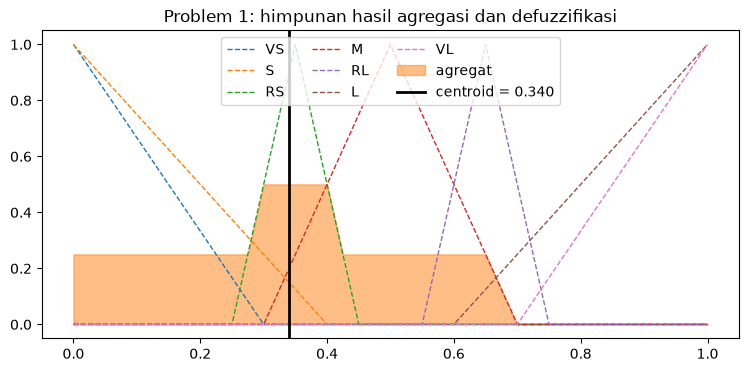

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for k, y in mf['n'].items():
    ax.plot(x, y, '--', lw=1, label=k)
ax.fill_between(x, agg0, color='tab:orange', alpha=.5, label='agregat')
ax.axvline(n0, color='k', lw=2, label=f'centroid = {n0:.3f}')
ax.set_title('Problem 1: himpunan hasil agregasi dan defuzzifikasi'); ax.legend(ncol=3)
plt.show()

## 5. Problem 2: ρ = 0, semua kombinasi m dan s
Untuk ρ=0, aturan 1 (ρ.L → n.S) selalu menyala penuh (derajat 1), sedangkan aturan 2 dan 3 mati. Sisanya ditentukan oleh m dan s. Kita hitung `n` di grid 51×51 dari m dan s, lalu gambar permukaan 3D.

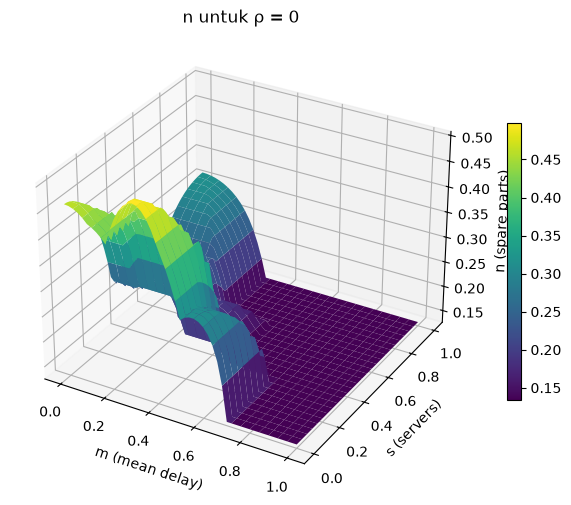

n minimum = 0.133, maksimum = 0.500
n di (m=0, s=0)     = 0.462
n di (m=0, s=1)     = 0.316
n di (m=0.5, s=0.5) = 0.133
n di (m=1, s=1)     = 0.133


In [7]:
g = np.linspace(0, 1, 51)
M, S = np.meshgrid(g, g)
N = np.array([[infer(mi, si, 0)[0] for mi in g] for si in g])

fig = plt.figure(figsize=(9, 6)); ax = fig.add_subplot(projection='3d')
surf = ax.plot_surface(M, S, N, cmap='viridis')
ax.set_xlabel('m (mean delay)'); ax.set_ylabel('s (servers)'); ax.set_zlabel('n (spare parts)')
ax.set_title('n untuk ρ = 0'); fig.colorbar(surf, shrink=.6); plt.show()

print('n minimum = %.3f, maksimum = %.3f' % (np.nanmin(N), np.nanmax(N)))
print('n di (m=0, s=0)     = %.3f' % N[0, 0])
print('n di (m=0, s=1)     = %.3f' % N[-1, 0])
print('n di (m=0.5, s=0.5) = %.3f' % N[25, 25])
print('n di (m=1, s=1)     = %.3f' % N[-1, -1])

**Insight dari permukaan 3D (ρ = 0):**

1. **Puncak di pojok s kecil, m pendek.** Nilai tertinggi n ≈ 0.50 muncul saat s ≈ 0 dan m ≈ 0.3. Masuk akal: petugas sedikit (perbaikan lambat) tetapi pelanggan menuntut tunggu singkat, sehingga butuh banyak stok (aturan 4 dan 5, konsekuen VL/L).
2. **n turun ketika m naik.** Semakin lama pelanggan mau menunggu, semakin sedikit stok yang perlu disiapkan. Untuk s = 0, n ≈ 0.44–0.50 selama m ≤ 0.4, turun ke ≈ 0.31 di m = 0.5–0.6, lalu ke 0.13 mulai m ≥ 0.7.
3. **n turun ketika s naik (secara umum).** Lebih banyak petugas memperbaiki suku cadang lebih cepat, jadi stok awal bisa lebih kecil. Pada m = 0, n turun dari 0.46 (s = 0) ke ≈ 0.24 (s = 0.7).
4. **Dasar datar di n ≈ 0.133.** Untuk m ≥ 0.7 (di luar rentang `m.M`) dan juga di daerah m dan s sama-sama besar, tidak ada aturan m–s yang menyala. Yang tersisa hanya aturan 1 (ρ.L → n.S, derajat 1), dan centroid segitiga `[0, 0, 0.4]` adalah 0.4/3 ≈ 0.133. Ini **artefak model**, bukan fakta tentang stok: aturan tidak mencakup m > 0.7.
5. **Tidak monoton sempurna.** Pada m kecil, n turun sampai s ≈ 0.7 lalu naik lagi ke ≈ 0.32 di s = 1. Penyebabnya bentuk MF: di s ≈ 0.7 himpunan `M` sudah habis sementara `L` baru mulai naik, sehingga aturan m–s menyala lemah dan aturan 1 (selalu penuh) menarik centroid ke bawah. Saat `L` penuh (s = 1), aturan 10 (n.M) kembali berpengaruh. Jadi lekukan itu efek tumpang-tindih MF dan agregasi centroid, bukan pola nyata.

**Kesimpulan:** tren utamanya sesuai intuisi (butuh stok lebih banyak saat petugas sedikit dan waktu tunggu harus singkat), tetapi bentuk permukaan juga dipengaruhi pilihan MF dan celah di basis aturan, jadi sebelum dipakai nyata, MF dan aturan perlu divalidasi dengan data servis.

## 6. Kasus tambahan: risiko kredit pinjaman
Kasus lain dengan alur yang sama: sebuah bank memutuskan **skor risiko** (0–100) dari **pendapatan bulanan** (juta rupiah) dan **rasio utang** terhadap pendapatan (0–1). Kali ini memakai API `skfuzzy.control` (`Antecedent`, `Consequent`, `Rule`), yang membungkus langkah 1–5 di atas.

Logika aturan: pendapatan tinggi dan utang rendah → risiko rendah; pendapatan rendah dan utang tinggi → risiko tinggi; kombinasi di antaranya menyesuaikan (9 aturan = 3×3). Bentuk MF dan aturan di sini adalah asumsi saya, bukan data bank.

In [8]:
from skfuzzy import control as ctrl

inc  = ctrl.Antecedent(np.arange(0, 10.01, .01), 'pendapatan')
dti  = ctrl.Antecedent(np.arange(0, 1.001, .001), 'rasio_utang')
risk = ctrl.Consequent(np.arange(0, 101, 1), 'risiko')

inc['rendah'], inc['sedang'], inc['tinggi'] = (fuzz.trimf(inc.universe, p) for p in ([0, 0, 5], [2, 5, 8], [5, 10, 10]))
dti['rendah'], dti['sedang'], dti['tinggi'] = (fuzz.trimf(dti.universe, p) for p in ([0, 0, .5], [.2, .5, .8], [.5, 1, 1]))
risk['rendah'], risk['sedang'], risk['tinggi'] = (fuzz.trimf(risk.universe, p) for p in ([0, 0, 50], [25, 50, 75], [50, 100, 100]))

table = {  # (pendapatan, rasio_utang): risiko
    ('tinggi', 'rendah'): 'rendah', ('tinggi', 'sedang'): 'rendah', ('tinggi', 'tinggi'): 'sedang',
    ('sedang', 'rendah'): 'rendah', ('sedang', 'sedang'): 'sedang', ('sedang', 'tinggi'): 'tinggi',
    ('rendah', 'rendah'): 'sedang', ('rendah', 'sedang'): 'tinggi', ('rendah', 'tinggi'): 'tinggi',
}
sim = ctrl.ControlSystemSimulation(ctrl.ControlSystem(
    [ctrl.Rule(inc[a] & dti[b], risk[c]) for (a, b), c in table.items()]))

def skor(pendapatan, rasio):
    sim.input['pendapatan'], sim.input['rasio_utang'] = pendapatan, rasio
    sim.compute()
    return sim.output['risiko']

for nama, p, r in [('Pemohon A', 9, .1), ('Pemohon B', 5, .5), ('Pemohon C', 2, .8)]:
    print(f'{nama}: pendapatan {p} jt, rasio utang {r:.0%} -> risiko {skor(p, r):.1f}/100')

Pemohon A: pendapatan 9 jt, rasio utang 10% -> risiko 17.2/100
Pemohon B: pendapatan 5 jt, rasio utang 50% -> risiko 50.0/100
Pemohon C: pendapatan 2 jt, rasio utang 80% -> risiko 81.4/100


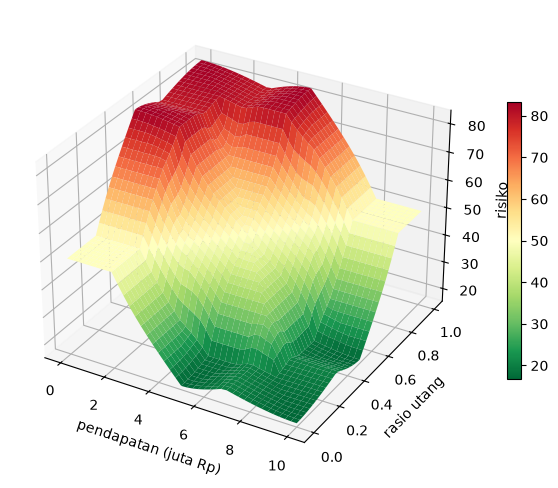

In [9]:
P, R = np.meshgrid(np.linspace(0, 10, 41), np.linspace(0, 1, 41))
Z = np.vectorize(skor)(P, R)
fig = plt.figure(figsize=(9, 6)); ax = fig.add_subplot(projection='3d')
surf = ax.plot_surface(P, R, Z, cmap='RdYlGn_r')
ax.set_xlabel('pendapatan (juta Rp)'); ax.set_ylabel('rasio utang'); ax.set_zlabel('risiko')
fig.colorbar(surf, shrink=.6); plt.show()

**Penjelasan kasus tambahan.** Langkahnya sama dengan Problem 1: (1) tiap input difuzzifikasi ke rendah/sedang/tinggi, (2) 9 aturan menyala sebagian sesuai derajatnya, (3) konsekuen dipotong, (4) diagregasi dengan union, (5) centroid memberi skor tunggal. Hasilnya: pemohon A (pendapatan tinggi, utang kecil) berisiko rendah, pemohon C (pendapatan kecil, utang besar) berisiko tinggi, dan pemohon B di tengah. Permukaan 3D naik halus ketika pendapatan turun dan rasio utang naik; kehalusan itu keunggulan fuzzy dibanding aturan IF-ELSE yang melompat di ambang batas.

## Keterbatasan
- Bentuk MF segitiga adalah asumsi saya karena soal hanya memberi rentang; bentuk lain (trapesium) bisa memberi n yang berbeda.
- Kasus kredit memakai aturan dan angka rekaan, hanya untuk demonstrasi.